# UTS Machine Learning - Milestone 1
## Analisis Sentimen Ulasan Berbahasa Indonesia (NusaX-Senti) dengan Classical Machine Learning

**Kelompok:** Sinergi
**Anggota:** Melva Romaulina Br Sitorus (231110028)
Hotnida Junita Pasaribu (221111292)
Karin Kenisa Br Sitepu (231111550)

**Project ID / Topik:** A14 - Text Mining: Sentimen Ulasan

## 0. Setup dan Reproducibility
Seed ditetapkan sekali di sini dan dipakai di semua model dan pembagian data.

In [25]:
import re, sys, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from collections import Counter

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

print("Python  :", sys.version.split()[0], "|", platform.platform())
print("pandas  :", pd.__version__, "| numpy:", np.__version__)
print("sklearn :", sklearn.__version__)
print("matplotlib:", matplotlib.__version__, "| seaborn:", sns.__version__)
print("SEED    :", SEED)

Python  : 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
pandas  : 2.2.3 | numpy: 2.4.6
sklearn : 1.6.1
matplotlib: 3.10.0 | seaborn: 0.13.2
SEED    : 42


## A. Problem Formulation

**Masalah.** Ulasan dan komentar berbahasa Indonesia di platform online jumlahnya sangat besar sehingga tidak praktis dibaca satu per satu. Memahami sentimen sebuah ulasan penting karena ulasan menjadi salah satu sumber informasi utama tentang pengalaman pengguna. Bagi pemilik usaha atau penyedia layanan, proporsi ulasan positif, netral, dan negatif dapat menunjukkan bagian layanan yang disukai dan bagian yang perlu diperbaiki, tanpa harus membaca ribuan ulasan satu per satu. Bagi pihak lain, seperti calon pelanggan atau pengelola reputasi suatu merek, ringkasan sentimen membantu memantau perubahan opini dari waktu ke waktu dan mendeteksi keluhan lebih cepat. Karena volume ulasan terus bertambah dan bahasanya sering informal, diperlukan metode otomatis yang dapat mengelompokkan ulasan ke dalam kelas sentimen secara konsisten. Proyek ini menjadi langkah awal untuk melihat seberapa jauh metode machine learning sederhana dapat melakukan hal tersebut pada teks berbahasa Indonesia.

**Tujuan proyek.** Membangun model classical machine learning yang mengklasifikasikan sebuah teks ulasan berbahasa Indonesia ke dalam salah satu dari tiga kelas sentimen: *negative*, *neutral*, atau *positive*.

**Target.** Kolom `label` (3 kelas, kategorikal).

**Fitur.** Kolom `text` yang diubah menjadi representasi numerik (TF-IDF dan fitur turunan).

**Jenis pendekatan.** Supervised learning - klasifikasi multikelas pada teks (text mining), menggunakan classical machine learning (bukan deep learning).

**Pertanyaan utama.** Seberapa baik masalah ini dapat diselesaikan oleh baseline sederhana, dan apakah model kandidat lain memberikan manfaat yang nyata dibanding baseline?

**Batasan proyek.**
1. Hanya classical machine learning (tanpa deep learning), sesuai ruang lingkup mata kuliah.
2. Hanya subset bahasa Indonesia dari NusaX-Senti; dataset dan masalah tidak diganti selama proyek berlangsung.
3. Hanya tiga kelas sentimen (negative, neutral, positive).
4. Milestone 1 tidak mencakup tuning menyeluruh, pemilihan model final, dan analisis error lengkap; hasil di notebook ini bersifat awal.
5. Data kecil (600 teks dev, 400 teks test) sehingga estimasi performa tidak stabil dan harus dibaca bersama simpangan baku antar-fold.
6. Preprocessing belum mencakup stemming dan normalisasi slang.

## B. Dataset dan Data Understanding

| Informasi | Keterangan |
|---|---|
| Nama dataset | NusaX-Senti (subset bahasa Indonesia) |
| Sumber | IndoNLP / NusaX (Winata et al., EACL 2023) |
| Link | https://github.com/IndoNLP/nusax/tree/main/datasets/sentiment |
| Asal data | Diturunkan dari SmSA (komentar dan ulasan dari berbagai platform online berbahasa Indonesia) |
| Lisensi | CC BY-SA 4.0 |
| Unit observasi | Satu teks ulasan/komentar |
| Target | `label`: negative / neutral / positive |
| Pembagian resmi | train, valid, test (file terpisah) |

Dataset **tidak** dikopi ke repository; notebook mengunduh langsung dari sumber sehingga mudah ditelusuri.

In [26]:
BASE = "https://raw.githubusercontent.com/IndoNLP/nusax/main/datasets/sentiment/indonesian/"
train = pd.read_csv(BASE + "train.csv")
valid = pd.read_csv(BASE + "valid.csv")
test  = pd.read_csv(BASE + "test.csv")

print("Ukuran  train/valid/test :", train.shape, valid.shape, test.shape)
print("Kolom                    :", list(train.columns))
print("\nTipe data:\n", train.dtypes)
train.sample(5, random_state=SEED)

Ukuran  train/valid/test : (500, 3) (100, 3) (400, 3)
Kolom                    : ['id', 'text', 'label']

Tipe data:
 id        int64
text     object
label    object
dtype: object


,id,text,label
361,722,Kemarin mereka mendaftar beasiswa djarum,neutral
73,51,"Peresmian pengoperasian kereta api bandara oleh presiden ri dengan simbolis, penekanan tombol sirine yang menyuaraka...",neutral
374,634,Steiknya lumayanlah enak. Warung ini cocok buat pelajar atau mahasiswa hehehe karena harganya terjangkau. Untuk maka...,positive
155,506,"Ingin bantu kasih hubungan infonya, tapi kuota internet saya terbatas.",neutral
104,656,"Sangat melelahkan, balik pergi ke kampus sore sekali ditambah kerja kelompok yang tidak ada abisnya, deadline tugas ...",negative


### Pembagian data dan alasannya
- `train` (500) dan `valid` (100) digabung menjadi **dev set (600)** yang dipakai untuk memilih fitur dan model lewat **Stratified 5-Fold Cross-Validation**. Dataset sangat kecil, jadi satu kali split validation 100 data kurang stabil.
- `test` (400) **tidak disentuh** sampai tahap akhir dan hanya dipakai untuk evaluasi model terpilih (dan baseline sebagai pembanding), supaya test set tidak dipakai berulang kali untuk memilih model.

In [27]:
dev = pd.concat([train, valid], ignore_index=True)
X_dev, y_dev = dev["text"], dev["label"]
X_test, y_test = test["text"], test["label"]
LABELS = ["negative", "neutral", "positive"]
print("Dev:", dev.shape, "| Test:", test.shape)

Dev: (600, 3) | Test: (400, 3)


## C. EDA dan Initial Findings
Semua pemeriksaan EDA di bawah ini dilakukan pada **dev set** (test set tidak dilihat).

,jumlah,persen
label,,
negative,230,38.3
neutral,143,23.8
positive,227,37.8


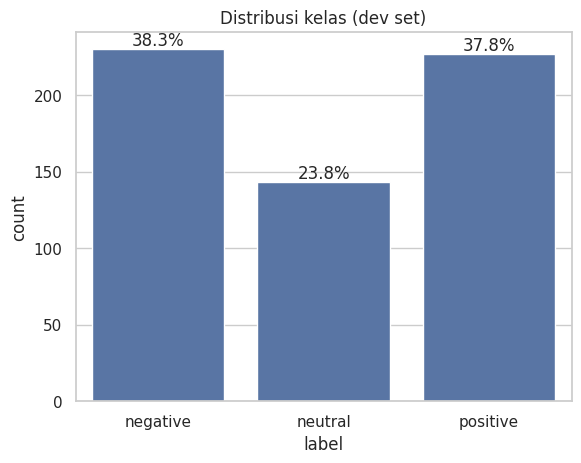

In [28]:
# C.1 Distribusi kelas
cnt = dev["label"].value_counts().reindex(LABELS)
pct = (cnt / cnt.sum() * 100).round(1)
display(pd.DataFrame({"jumlah": cnt, "persen": pct}))

ax = sns.countplot(data=dev, x="label", order=LABELS)
for p, v in zip(ax.patches, pct):
    ax.annotate(f"{v}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribusi kelas (dev set)"); plt.show()

,n_words,n_chars
count,600.00,600.00
mean,23.05,152.93
std,14.37,95.18
min,4.00,27.00
25%,12.00,79.75
50%,19.00,124.00
75%,31.00,204.75
max,77.00,498.00


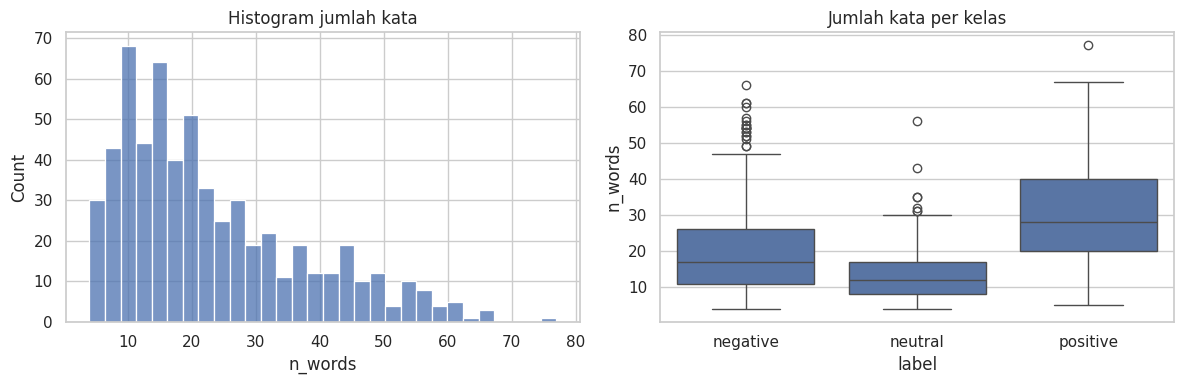

,mean,median,max
label,,,
negative,21.7,17.0,66
neutral,13.8,12.0,56
positive,30.2,28.0,77


In [29]:
# C.2 Panjang teks
dev["n_words"] = dev["text"].str.split().str.len()
dev["n_chars"] = dev["text"].str.len()
display(dev[["n_words", "n_chars"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=dev, x="n_words", bins=30, ax=axes[0]); axes[0].set_title("Histogram jumlah kata")
sns.boxplot(data=dev, x="label", y="n_words", order=LABELS, ax=axes[1]); axes[1].set_title("Jumlah kata per kelas")
plt.tight_layout(); plt.show()
display(dev.groupby("label")["n_words"].agg(["mean", "median", "max"]).round(1).reindex(LABELS))

In [30]:
# C.3 Kata paling sering per kelas (stopword umum dibuang agar lebih informatif; hanya untuk EDA)
STOP_ID = set("""
yang dan di ke dari ini itu untuk dengan pada adalah juga dalam atau saya aku kami kita kamu anda dia mereka
ada akan sudah telah bisa dapat oleh agar karena sebagai lebih sangat lagi saja pun nya the
""".split())
NEGATIONS = {"tidak", "tak", "bukan", "belum", "jangan", "tanpa", "kurang"}   # penting untuk sentimen, tidak dibuang

def simple_tokens(t):
    t = re.sub(r"https?://\S+|www\.\S+", " ", str(t).lower())
    return re.findall(r"[a-z]+", t)

rows = {}
for lab in LABELS:
    c = Counter(w for t in dev.loc[dev.label == lab, "text"] for w in simple_tokens(t) if w not in STOP_ID)
    rows[lab] = [f"{w} ({n})" for w, n in c.most_common(12)]
display(pd.DataFrame(rows))

,negative,neutral,positive
0,tidak (155),tidak (16),enak (136)
1,makan (40),banyak (9),makan (95)
2,tempat (33),kalau (7),makanan (82)
3,makanan (32),makanan (7),tempat (80)
4,tapi (32),bulan (6),tidak (70)
5,orang (31),mau (6),sini (59)
6,banyak (31),tolong (6),cukup (51)
7,sekali (28),ya (6),tempatnya (50)
8,jadi (28),kasih (6),banget (47)
9,enak (27),kembali (6),banyak (45)


In [31]:
# C.4 Data Quality Findings (angka dihitung otomatis dari data)
n = len(dev)
dup_in_dev   = int(dev["text"].duplicated().sum())
overlap_test = len(set(dev["text"]) & set(test["text"]))
n_url   = int(dev["text"].str.contains(r"https?://|www\.", regex=True).sum())
n_mention = int(dev["text"].str.contains(r"[@#]\w+", regex=True).sum())
n_digit = int(dev["text"].str.contains(r"\d", regex=True).sum())
n_upper = int(dev["text"].str.contains(r"[A-Z]", regex=True).sum())
n_short = int((dev["n_words"] <= 5).sum())
skew    = dev["n_words"].skew()
neutral_pct = pct["neutral"]

findings = pd.DataFrame([
    ["Missing value", f"{int(dev.isna().sum().sum())} sel kosong", "Tidak perlu imputasi jika 0"],
    ["Data duplikat", f"{dup_in_dev} teks duplikat di dev; {overlap_test} teks sama antara dev dan test", "Jika ada irisan dev-test, itu risiko leakage"],
    ["Kelas tidak seimbang", f"neutral hanya {neutral_pct}% dari dev", "Accuracy bisa menyesatkan; pakai macro-F1, periksa recall kelas neutral"],
    ["Distribusi panjang teks miring", f"skewness jumlah kata = {skew:.2f}; median {dev['n_words'].median():.0f}, maks {dev['n_words'].max()}", "Teks panjang bisa mendominasi bobot TF-IDF; pakai normalisasi (L2) dan sublinear TF"],
    ["Noise format teks", f"URL: {n_url}, mention/hashtag: {n_mention}, mengandung angka: {n_digit}, mengandung huruf kapital: {n_upper}", "Perlu case folding dan pembersihan pola non-informatif"],
    ["Teks sangat pendek", f"{n_short} teks <= 5 kata", "Informasi terbatas; n-gram bisa membantu menangkap frasa"],
], columns=["Temuan", "Bukti (dari data)", "Implikasi"])
findings.index = range(1, len(findings) + 1)
findings

,Temuan,Bukti (dari data),Implikasi
1,Missing value,0 sel kosong,Tidak perlu imputasi jika 0
2,Data duplikat,0 teks duplikat di dev; 0 teks sama antara dev dan test,"Jika ada irisan dev-test, itu risiko leakage"
3,Kelas tidak seimbang,neutral hanya 23.8% dari dev,"Accuracy bisa menyesatkan; pakai macro-F1, periksa recall kelas neutral"
4,Distribusi panjang teks miring,"skewness jumlah kata = 0.99; median 19, maks 77",Teks panjang bisa mendominasi bobot TF-IDF; pakai normalisasi (L2) dan sublinear TF
5,Noise format teks,"URL: 0, mention/hashtag: 0, mengandung angka: 108, mengandung huruf kapital: 600",Perlu case folding dan pembersihan pola non-informatif
6,Teks sangat pendek,17 teks <= 5 kata,Informasi terbatas; n-gram bisa membantu menangkap frasa


### Interpretasi EDA

Format: **Temuan + Bukti + Interpretasi + Implikasi**.

1. **Distribusi kelas.** Negative 230 (38.3%), neutral 143 (23.8%), positive 227 (37.8%). Neutral adalah kelas minoritas, sehingga accuracy bisa menyesatkan; gunakan macro-F1 dan recall per kelas.
2. **Panjang teks.** Median neutral 12 kata, negative 17, positive 28, dan distribusi miring ke kanan (skewness 0.99). Panjang teks berkaitan dengan kelas, jadi layak diuji sebagai fitur (bagian E), tetapi berisiko menjadi jalan pintas; gunakan sublinear TF dan normalisasi L2.
3. **Kata dominan.** Kata "tidak" sangat sering pada negative (155) tetapi juga muncul 70 kali pada positive; "enak" teratas pada positive. Kata bertema kuliner mendominasi positive dan negative, sedangkan pada neutral hanya "makanan" yang masuk daftar. Negasi tidak boleh dibuang, dan ada dugaan perbedaan topik antar kelas (diperiksa di H.7).
4. **Data quality.** 0 missing value, 0 duplikat, 0 irisan dev-test; imbalance ringan; 108 teks mengandung angka; 600 teks mengandung huruf kapital; 17 teks berisi 5 kata atau kurang. Keputusan: case folding dan hapus angka; tidak perlu imputasi atau deduplikasi; pembersihan URL/mention tetap disiapkan walau 0 ditemukan.

## D. Preprocessing

Langkah dan alasan:
1. **Case folding** (huruf kecil): "Enak" dan "enak" harus dianggap kata yang sama.
2. **Hapus URL, mention/hashtag, angka, tanda baca**: tidak membawa informasi sentimen yang konsisten.
3. **Normalisasi spasi.**
4. **Tidak membuang kata negasi** (mis. *tidak*, *kurang*) karena membalik makna sentimen.
5. **Tidak ada stemming/slang normalizer** pada tahap ini (keterbatasan, dicatat untuk rencana UAS).

**Pencegahan data leakage:** fungsi pembersihan bersifat *stateless* (tidak mempelajari apa pun dari data). Pembelajaran kosakata dan bobot IDF dilakukan oleh `TfidfVectorizer` **di dalam Pipeline**, sehingga pada setiap fold CV hanya di-*fit* pada data training fold tersebut.

In [32]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"[@#]\w+")

def clean_text(t):
    t = str(t).lower()
    t = URL_RE.sub(" ", t)
    t = MENTION_RE.sub(" ", t)
    t = re.sub(r"\d+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

STOP_MODEL = STOP_ID - NEGATIONS
def clean_stop(t):
    return " ".join(w for w in clean_text(t).split() if w not in STOP_MODEL)

demo = dev.sample(5, random_state=SEED)[["text"]].copy()
demo["setelah_clean"] = demo["text"].apply(clean_text)
demo

,text,setelah_clean
110,Aku dan suami biasanya menginap di jimbaran saat berkunjung ke bali,aku dan suami biasanya menginap di jimbaran saat berkunjung ke bali
419,Sangat kecewa sekali karena liga champions tidak disiarkan di channel manapun baik channel lokal ataupun channel ola...,sangat kecewa sekali karena liga champions tidak disiarkan di channel manapun baik channel lokal ataupun channel ola...
565,Toyota mengeluarkan produk terbarunya.,toyota mengeluarkan produk terbarunya
77,"Baru pakai berapa hari langsung hang, power bank tidak bisa di pake apa-apa. Harus bawa ke tempat servis.",baru pakai berapa hari langsung hang power bank tidak bisa di pake apa apa harus bawa ke tempat servis
181,Tempat ini terkenal banget di kalangan mahasiswa. Karena selain enak harganya juga termasuk murah kalau menurut saya...,tempat ini terkenal banget di kalangan mahasiswa karena selain enak harganya juga termasuk murah kalau menurut saya ...


## E. Initial Feature Engineering

Representasi dasar adalah **TF-IDF** (`sublinear_tf=True`). Diuji beberapa transformasi fitur dengan model yang sama (Logistic Regression) dan strategi validasi yang sama:

| Kode | Deskripsi | Alasan / dampak yang diharapkan |
|---|---|---|
| `word_1gram` | TF-IDF kata unigram | Representasi paling sederhana (dipakai baseline) |
| `word_1-2gram` | TF-IDF kata unigram + bigram | Menangkap frasa pendek, mis. "tidak enak" |
| `char_2-5gram` | TF-IDF karakter (2-5) | Lebih tahan terhadap salah ketik/ejaan tidak baku |
| `word_1-2gram_stop` | Seperti 1-2gram, stopword dibuang (negasi dipertahankan) | Mengurangi kata umum yang tidak informatif |
| `word_1-2gram_len` | 1-2gram + fitur panjang teks (jumlah kata, karakter, "!" , "?") | Menguji apakah panjang/ekspresi teks membantu |

In [33]:
def length_feats(texts):
    s = pd.Series(list(texts))
    return np.c_[s.str.split().str.len(), s.str.len(), s.str.count("!"), s.str.count(r"\?")]

def make_features(kind):
    kw = dict(sublinear_tf=True)
    if kind == "word_1gram":
        return TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 1), **kw)
    if kind == "word_1-2gram":
        return TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), **kw)
    if kind == "char_2-5gram":
        return TfidfVectorizer(preprocessor=clean_text, analyzer="char_wb", ngram_range=(2, 5), **kw)
    if kind == "word_1-2gram_stop":
        return TfidfVectorizer(preprocessor=clean_stop, ngram_range=(1, 2), **kw)
    if kind == "word_1-2gram_len":
        return FeatureUnion([
            ("tfidf", TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), **kw)),
            ("len", Pipeline([("f", FunctionTransformer(length_feats)),
                              ("s", StandardScaler(with_mean=False))])),
        ])
    raise ValueError(kind)

def make_model(name):
    return {
        "Dummy (majority)":       DummyClassifier(strategy="most_frequent"),
        "Logistic Regression":    LogisticRegression(max_iter=1000, random_state=SEED),
        "Logistic Reg (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
        "Multinomial NB":         MultinomialNB(),
        "Linear SVM":             LinearSVC(random_state=SEED),
        "Random Forest":          RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    }[name]

def make_pipe(feat_kind, model_name):
    return Pipeline([("feat", make_features(feat_kind)), ("clf", make_model(model_name))])

## G. Evaluation Design

- **Data:** dev set (600) untuk pemilihan; test set (400) disimpan untuk evaluasi akhir.
- **Validasi:** **Stratified 5-Fold** (shuffle, seed tetap) agar proporsi tiga kelas terjaga di tiap fold. Alasan: data kecil dan kelas tidak seimbang, jadi satu kali split kurang dapat dipercaya.
- **Metrik utama:** **macro-F1** (memperlakukan tiga kelas sama penting, sehingga kelas neutral yang minoritas tidak tertutupi). Metrik pendukung: accuracy, macro-precision, macro-recall, serta confusion matrix.
- **Kestabilan:** dilaporkan rata-rata dan standar deviasi skor antar-fold.
- **Eksperimen dicatat** otomatis ke `experiment_log` (model, fitur, seed, skor).

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "precision_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}
experiment_log = []

def run_cv(feat_kind, model_name, note=""):
    res = cross_validate(make_pipe(feat_kind, model_name), X_dev, y_dev, cv=cv, scoring=SCORING, n_jobs=1)
    row = {"run": f"#{len(experiment_log)+1:03d}", "model": model_name, "fitur": feat_kind, "seed": SEED,
           "validasi": "Stratified 5-Fold (dev=600)", "note": note}
    for m in SCORING:
        row[m + "_mean"] = res["test_" + m].mean()
        row[m + "_std"]  = res["test_" + m].std()
    row["_folds_f1"] = res["test_f1_macro"]
    experiment_log.append(row)
    return row

def show(rows, cols=("model", "fitur", "accuracy_mean", "precision_macro_mean", "recall_macro_mean", "f1_macro_mean", "f1_macro_std")):
    df = pd.DataFrame(rows)[list(cols)].round(4)
    return df

## E (lanjutan). Perbandingan Variasi Fitur
Model dikunci pada Logistic Regression; yang berubah hanya representasi fitur.

In [35]:
FEATS = ["word_1gram", "word_1-2gram", "char_2-5gram", "word_1-2gram_stop", "word_1-2gram_len"]
fe_rows = [run_cv(f, "Logistic Regression", note="uji fitur") for f in FEATS]
fe_table = show(fe_rows).set_index("fitur")
display(fe_table)

BEST_FEAT = fe_table["f1_macro_mean"].idxmax()
print("Fitur terbaik berdasarkan macro-F1 CV:", BEST_FEAT)
print("(Boleh dioverride manual, tetapi tulis alasannya di laporan.)")

,model,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std
fitur,,,,,,
word_1gram,Logistic Regression,0.7750,0.8006,0.7380,0.7459,0.0384
word_1-2gram,Logistic Regression,0.7233,0.7698,0.6604,0.6422,0.0469
char_2-5gram,Logistic Regression,0.7867,0.8102,0.7631,0.7741,0.0337
word_1-2gram_stop,Logistic Regression,0.7317,0.7784,0.6706,0.6557,0.0286
word_1-2gram_len,Logistic Regression,0.7233,0.7202,0.7078,0.7113,0.0554


Fitur terbaik berdasarkan macro-F1 CV: char_2-5gram
(Boleh dioverride manual, tetapi tulis alasannya di laporan.)


**Interpretasi:** `char_2-5gram` tertinggi (macro-F1 0.7741) dibanding unigram (0.7459). Selisih 0.0282 lebih kecil daripada simpangan baku antar-fold (0.0337 sampai 0.0384), jadi belum dapat dikatakan pasti lebih baik. Bigram kata justru menurunkan skor cukup jauh (0.6422); penyebabnya belum diuji (dugaan: ruang fitur membesar pada data hanya 600 teks). Penghapusan stopword tidak memberi perbaikan nyata (0.6557 dibanding 0.6422). Fitur panjang teks menaikkan 1-2gram dari 0.6422 ke 0.7113, tetapi tetap di bawah unigram.

## F. Baseline dan Initial Candidate Models

- **Dummy (majority class):** bukan model sungguhan, hanya batas bawah untuk memastikan model benar-benar belajar.
- **Baseline: TF-IDF unigram + Logistic Regression.** Sederhana, cepat, dan standar untuk klasifikasi teks.
- **Kandidat 1: Multinomial Naive Bayes** - cocok untuk fitur frekuensi/TF-IDF dan sangat cepat pada data kecil.
- **Kandidat 2: Linear SVM** - umumnya kuat pada ruang fitur teks berdimensi tinggi.
- **Kandidat 3: Random Forest** - perwakilan ensemble berbasis pohon; dibandingkan secara adil dengan validasi yang sama.

Baseline adalah Logistic Regression + `word_1gram`. Agar perbandingan konsisten, **setiap model (Logistic Regression, Naive Bayes, Linear SVM, Random Forest) diuji pada dua fitur**: `word_1gram` (fitur baseline) dan `BEST_FEAT` (fitur terbaik dari tahap E). Dengan begitu perbedaan antar model dapat dibaca pada fitur yang sama, dan pengaruh fitur dapat dibaca pada model yang sama.

In [36]:
model_rows = [run_cv("word_1gram", "Dummy (majority)", note="batas bawah")]
FEATS_COMPARE = list(dict.fromkeys(["word_1gram", BEST_FEAT]))
for f in FEATS_COMPARE:
    for m in ["Logistic Regression", "Multinomial NB", "Linear SVM", "Random Forest"]:
        note = "BASELINE" if (f == "word_1gram" and m == "Logistic Regression") else "kandidat"
        model_rows.append(run_cv(f, m, note=note))

compare = show(model_rows)
display(compare)

print("Macro-F1 rata-rata CV (baris = model, kolom = fitur):")
pivot = (pd.DataFrame(model_rows).query("model != 'Dummy (majority)'")
         .pivot(index="model", columns="fitur", values="f1_macro_mean").round(4))
pivot

,model,fitur,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std
0,Dummy (majority),word_1gram,0.3833,0.1278,0.3333,0.1847,0.0000
1,Logistic Regression,word_1gram,0.7750,0.8006,0.7380,0.7459,0.0384
2,Multinomial NB,word_1gram,0.6483,0.7428,0.5839,0.5473,0.0558
3,Linear SVM,word_1gram,0.7583,0.7517,0.7347,0.7389,0.0295
4,Random Forest,word_1gram,0.7617,0.7584,0.7503,0.7522,0.0333
5,Logistic Regression,char_2-5gram,0.7867,0.8102,0.7631,0.7741,0.0337
6,Multinomial NB,char_2-5gram,0.5750,0.5303,0.5061,0.4344,0.0305
7,Linear SVM,char_2-5gram,0.7783,0.7769,0.7645,0.7679,0.0399
8,Random Forest,char_2-5gram,0.7433,0.7568,0.7224,0.7314,0.0308


Macro-F1 rata-rata CV (baris = model, kolom = fitur):


fitur,char_2-5gram,word_1gram
model,,
Linear SVM,0.7679,0.7389
Logistic Regression,0.7741,0.7459
Multinomial NB,0.4344,0.5473
Random Forest,0.7314,0.7522


**Interpretasi perbandingan model:** Pada fitur `word_1gram`, Logistic Regression (0.7459), Linear SVM (0.7389), dan Random Forest (0.7522) berselisih paling besar sekitar 0.013, lebih kecil daripada simpangan baku antar-fold, jadi ketiganya setara pada fitur ini; Multinomial NB jauh lebih rendah (0.5473). Pada `char_2-5gram`, Logistic Regression (0.7741) dan Linear SVM (0.7679) setara, Random Forest lebih rendah (0.7314), dan NB paling rendah (0.4344). NB lemah pada kedua fitur; penyebabnya belum diselidiki. Random Forest sebagai ensemble tidak memberi keunggulan pasti atas baseline pada fitur yang sama (0.7522 dibanding 0.7459), dan waktu komputasi tidak diukur di notebook ini. Skor tertinggi: Logistic Regression + `char_2-5gram`, dengan catatan keunggulannya tipis dan model final belum ditetapkan.

## H. Initial Results and Analysis
### H.1 Kestabilan antar-fold

In [37]:
cand_df = pd.DataFrame(model_rows)
cand_only = cand_df[(cand_df.note == "kandidat") | (cand_df.note == "BASELINE")]
best_idx = cand_only["f1_macro_mean"].idxmax()
BEST_MODEL, BEST_MODEL_FEAT = cand_df.loc[best_idx, "model"], cand_df.loc[best_idx, "fitur"]
print("Model terbaik di CV (macro-F1):", BEST_MODEL, "|", BEST_MODEL_FEAT)

fold_table = pd.DataFrame({
    "Baseline (LR + word_1gram)": cand_df[cand_df.note == "BASELINE"].iloc[0]["_folds_f1"],
    f"{BEST_MODEL} + {BEST_MODEL_FEAT}": cand_df.loc[best_idx, "_folds_f1"],
}, index=[f"Fold {i}" for i in range(1, 6)])
fold_table.loc["Rata-rata"] = fold_table.iloc[:5].mean()
fold_table.loc["Std. deviasi"] = fold_table.iloc[:5].std(ddof=0)
fold_table.round(4)

Model terbaik di CV (macro-F1): Logistic Regression | char_2-5gram


,Baseline (LR + word_1gram),Logistic Regression + char_2-5gram
Fold 1,0.7352,0.7763
Fold 2,0.7133,0.7328
Fold 3,0.7992,0.8334
Fold 4,0.7001,0.7527
Fold 5,0.7815,0.7754
Rata-rata,0.7459,0.7741
Std. deviasi,0.0384,0.0337


**Interpretasi kestabilan:** Skor antar-fold bervariasi cukup besar: baseline 0.7001 sampai 0.7992 dan model terbaik 0.7328 sampai 0.8334 (rentang sekitar 0.10), sehingga satu kali split tidak dapat dipercaya. Model terbaik lebih tinggi pada fold 1 sampai 4 dan sedikit lebih rendah pada fold 5. Selisih rata-rata 0.0282 masih lebih kecil daripada simpangan baku, sehingga model terbaik cenderung lebih baik tetapi belum pasti.

### H.2 Imbalance: apakah kelas neutral dirugikan?
Distribusi sudah ditampilkan di bagian C. Di sini diperiksa recall per kelas dari prediksi out-of-fold, dan diuji **satu** strategi penanganan: `class_weight="balanced"`.

In [38]:
def oof_report(feat, model):
    pred = cross_val_predict(make_pipe(feat, model), X_dev, y_dev, cv=cv, n_jobs=1)
    p, r, f, s = precision_recall_fscore_support(y_dev, pred, labels=LABELS, zero_division=0)
    return pred, pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=LABELS)

pred_plain, rep_plain = oof_report(BEST_FEAT, "Logistic Regression")
pred_bal,   rep_bal   = oof_report(BEST_FEAT, "Logistic Reg (balanced)")
bal_row = run_cv(BEST_FEAT, "Logistic Reg (balanced)", note="uji imbalance")

print("LR tanpa class_weight (out-of-fold):"); display(rep_plain.round(3))
print("LR class_weight='balanced' (out-of-fold):"); display(rep_bal.round(3))
display(show([r for r in experiment_log if r["fitur"] == BEST_FEAT and r["model"].startswith("Logistic")]))

LR tanpa class_weight (out-of-fold):


,precision,recall,f1,support
negative,0.721,0.843,0.778,230
neutral,0.885,0.594,0.711,143
positive,0.821,0.850,0.835,227


LR class_weight='balanced' (out-of-fold):


,precision,recall,f1,support
negative,0.761,0.748,0.754,230
neutral,0.738,0.727,0.732,143
positive,0.820,0.841,0.830,227


,model,fitur,accuracy_mean,precision_macro_mean,recall_macro_mean,f1_macro_mean,f1_macro_std
0,Logistic Regression,char_2-5gram,0.7867,0.8102,0.7631,0.7741,0.0337
1,Logistic Regression,char_2-5gram,0.7867,0.8102,0.7631,0.7741,0.0337
2,Logistic Reg (balanced),char_2-5gram,0.7783,0.7738,0.7724,0.7717,0.0565


**Keputusan imbalance:** Pada model biasa, neutral punya precision tertinggi (0.885) tetapi recall terendah (0.594). Dengan `class_weight="balanced"`, recall neutral naik ke 0.727 tetapi precision turun ke 0.738; macro-F1 tidak membaik (0.7717 dibanding 0.7741) dan simpangan baku naik (0.0565 dibanding 0.0337). Efeknya adalah pergeseran precision-recall, bukan peningkatan keseluruhan, sehingga penanganan imbalance belum diperlukan pada tahap ini dan `class_weight` tidak dijadikan default.

### H.3 Confusion matrix model terbaik (out-of-fold pada dev set)

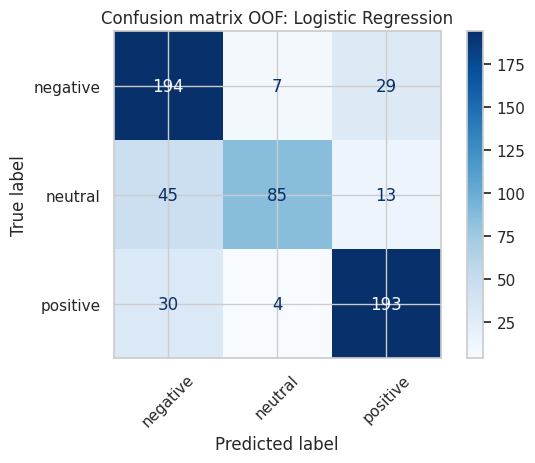

              precision    recall  f1-score   support

    negative      0.721     0.843     0.778       230
     neutral      0.885     0.594     0.711       143
    positive      0.821     0.850     0.835       227

    accuracy                          0.787       600
   macro avg      0.809     0.763     0.775       600
weighted avg      0.798     0.787     0.784       600



In [39]:
pred_best = cross_val_predict(make_pipe(BEST_MODEL_FEAT, BEST_MODEL), X_dev, y_dev, cv=cv, n_jobs=1)
ConfusionMatrixDisplay.from_predictions(y_dev, pred_best, labels=LABELS, cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion matrix OOF: {BEST_MODEL}"); plt.tight_layout(); plt.show()
print(classification_report(y_dev, pred_best, labels=LABELS, digits=3))

### H.4 Evaluasi akhir di test set (sekali saja)
Test set dipakai **hanya untuk baseline dan model terpilih**, dilatih ulang pada seluruh dev set (600). Ini bukan proses memilih model; pemilihan sudah selesai di CV.

,peran,model,fitur,accuracy,precision_macro,recall_macro,f1_macro
0,Baseline,Logistic Regression,word_1gram,0.7625,0.7737,0.7278,0.7353
1,Model terbaik CV,Logistic Regression,char_2-5gram,0.7675,0.7840,0.7334,0.7424


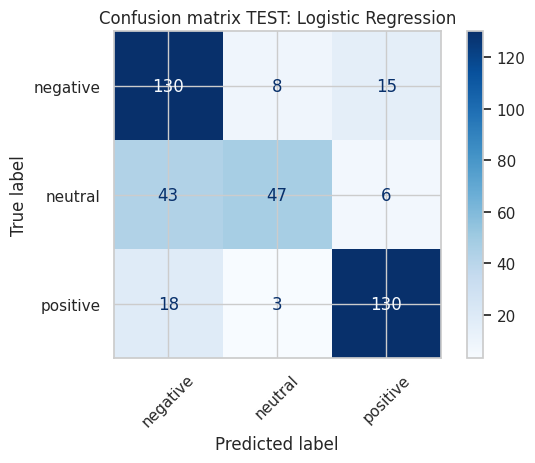

              precision    recall  f1-score   support

    negative      0.681     0.850     0.756       153
     neutral      0.810     0.490     0.610        96
    positive      0.861     0.861     0.861       151

    accuracy                          0.767       400
   macro avg      0.784     0.733     0.742       400
weighted avg      0.780     0.767     0.761       400



In [40]:
def test_eval(feat, model):
    pipe = make_pipe(feat, model).fit(X_dev, y_dev)
    pred = pipe.predict(X_test)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    return pred, {"model": model, "fitur": feat, "accuracy": accuracy_score(y_test, pred),
                  "precision_macro": p, "recall_macro": r, "f1_macro": f}

pred_base_t, res_base = test_eval("word_1gram", "Logistic Regression")
pred_best_t, res_best = test_eval(BEST_MODEL_FEAT, BEST_MODEL)
test_table = pd.DataFrame([{"peran": "Baseline", **res_base}, {"peran": "Model terbaik CV", **res_best}]).round(4)
display(test_table)

ConfusionMatrixDisplay.from_predictions(y_test, pred_best_t, labels=LABELS, cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion matrix TEST: {BEST_MODEL}"); plt.tight_layout(); plt.show()
print(classification_report(y_test, pred_best_t, labels=LABELS, digits=3))

### H.5 Tabel hasil gabungan (untuk laporan)

In [41]:
final_table = pd.DataFrame(experiment_log).drop(columns=["_folds_f1"]).round(4)
final_table

,run,model,fitur,seed,validasi,note,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
0,#001,Logistic Regression,word_1gram,42,Stratified 5-Fold (dev=600),uji fitur,0.7750,0.0312,0.8006,0.0418,0.7380,0.0346,0.7459,0.0384
1,#002,Logistic Regression,word_1-2gram,42,Stratified 5-Fold (dev=600),uji fitur,0.7233,0.0392,0.7698,0.0606,0.6604,0.0398,0.6422,0.0469
2,#003,Logistic Regression,char_2-5gram,42,Stratified 5-Fold (dev=600),uji fitur,0.7867,0.0314,0.8102,0.0384,0.7631,0.0315,0.7741,0.0337
3,#004,Logistic Regression,word_1-2gram_stop,42,Stratified 5-Fold (dev=600),uji fitur,0.7317,0.0193,0.7784,0.0234,0.6706,0.0198,0.6557,0.0286
4,#005,Logistic Regression,word_1-2gram_len,42,Stratified 5-Fold (dev=600),uji fitur,0.7233,0.0559,0.7202,0.0551,0.7078,0.0552,0.7113,0.0554
5,#006,Dummy (majority),word_1gram,42,Stratified 5-Fold (dev=600),batas bawah,0.3833,0.0000,0.1278,0.0000,0.3333,0.0000,0.1847,0.0000
6,#007,Logistic Regression,word_1gram,42,Stratified 5-Fold (dev=600),BASELINE,0.7750,0.0312,0.8006,0.0418,0.7380,0.0346,0.7459,0.0384
7,#008,Multinomial NB,word_1gram,42,Stratified 5-Fold (dev=600),kandidat,0.6483,0.0504,0.7428,0.0402,0.5839,0.0491,0.5473,0.0558
8,#009,Linear SVM,word_1gram,42,Stratified 5-Fold (dev=600),kandidat,0.7583,0.0284,0.7517,0.0277,0.7347,0.0295,0.7389,0.0295
9,#010,Random Forest,word_1gram,42,Stratified 5-Fold (dev=600),kandidat,0.7617,0.0310,0.7584,0.0390,0.7503,0.0298,0.7522,0.0333


### H.6 Error analysis awal
Sampel yang salah diprediksi (out-of-fold, model terbaik) diambil secara acak dengan seed tetap.

Contoh kategori penyebab yang bisa dipakai: kalimat ambigu/netral berisi opini campuran, negasi atau sarkasme, ejaan/slang tidak baku, teks sangat pendek, label yang diragukan.

In [42]:
wrong = dev.assign(pred=pred_best)
wrong = wrong[wrong["label"] != wrong["pred"]]
print(f"Salah prediksi: {len(wrong)} dari {len(dev)} ({len(wrong)/len(dev)*100:.1f}%)")

print("\nPasangan kesalahan (label asli -> prediksi):")
display(wrong.groupby(["label", "pred"]).size().sort_values(ascending=False).rename("jumlah").to_frame())

err_sample = wrong.sample(min(50, len(wrong)), random_state=SEED)[["id", "text", "label", "pred"]].copy()
err_sample["penyebab"] = ""      # <- ISI MANUAL
err_sample.to_csv("error_analysis_sample.csv", index=False)
err_sample.head(15)

Salah prediksi: 128 dari 600 (21.3%)

Pasangan kesalahan (label asli -> prediksi):


,,jumlah
label,pred,
neutral,negative,45
positive,negative,30
negative,positive,29
neutral,positive,13
negative,neutral,7
positive,neutral,4


,id,text,label,pred,penyebab
275,197,"Enkaolshop, terpercaya, barangnya bagus bagus",positive,negative,
201,22,Kami sekeluarga ke tempat ini karena hari sudah larut malam dan tidak ada resto lain yang buka. Ternyata jam 10 mala...,negative,positive,
110,279,Aku dan suami biasanya menginap di jimbaran saat berkunjung ke bali,neutral,negative,
153,540,Daripada ribut-ribut soal barang flash sale mending main poker online.,neutral,negative,
451,4,"Penasaran dengan ulasan orang, spesial cari waktu ke warung sale. Awalnya semangat. Menembus macet. Demilah. Tapi ke...",negative,positive,
276,301,"Aslinya ini basa berada di jalan karapitan setahu saya, sekarang memenag sudah tersebar di beberapa tempat di bandun...",negative,positive,
343,260,Saya sudah kirim email complaint karena telepon tidak masuk terus.,neutral,negative,
484,243,Menangkan hadiah keren cukup dengan mengikuti foto kontes baik untuk men di alfamart.,neutral,positive,
399,564,"Saya ke sini bersama beberapa teman untuk makan siang. Akses jalan menuju lokasi kafe ini sangat sempit dan terjal, ...",negative,positive,
133,683,Tolonglah pihak telkomsel di revisi harga-harga paket internetnya harganya selangit.,negative,neutral,


**Tabel ringkasan error analysis:** lihat bagian H.7 di bawah

### H.7 Kategorisasi error (DRAFT) dan analisis pendukung
Sampel 50 error di H.6 dipetakan ke kategori penyebab berdasarkan **pembacaan teks**. Ubah kategori pada kamus `ERR_CATEGORY` jika tidak setuju; tabel proporsi akan menyesuaikan otomatis. Kunci kamus adalah kolom `id` dataset.

In [43]:
ERR_LABELS = {
    "K1": "Kalimat netral (fakta/promosi/cerita tanpa opini) dibaca bersentimen",
    "K2": "Ulasan campuran: pujian dan keluhan dalam satu teks",
    "K3": "Keluhan implisit (narasi pengalaman buruk tanpa kata negatif kuat)",
    "K4": "Keluhan berbentuk permintaan/umpatan/slang",
    "K5": "Pujian yang memuat kata negasi",
    "K6": "Pujian pendek/informal, promosi, atau pengandaian",
}
ERR_CATEGORY = {197: 'K6', 22: 'K3', 279: 'K1', 540: 'K1', 4: 'K2', 301: 'K2', 260: 'K1', 243: 'K1', 564: 'K3', 683: 'K4', 428: 'K4', 257: 'K1', 596: 'K5', 852: 'K6', 270: 'K2', 409: 'K5', 157: 'K1', 286: 'K3', 308: 'K3', 914: 'K5', 228: 'K3', 766: 'K2', 730: 'K6', 364: 'K1', 57: 'K1', 881: 'K1', 812: 'K1', 473: 'K1', 6: 'K1', 570: 'K3', 393: 'K1', 581: 'K1', 322: 'K2', 842: 'K1', 930: 'K6', 536: 'K6', 829: 'K1', 838: 'K5', 71: 'K1', 887: 'K1', 261: 'K2', 471: 'K6', 637: 'K5', 478: 'K2', 532: 'K1', 384: 'K5', 568: 'K1', 506: 'K1', 58: 'K2', 523: 'K3'}

err_sample["kategori"] = err_sample["id"].map(ERR_CATEGORY)
assert err_sample["kategori"].notna().all(), "Ada id sampel yang belum dipetakan: sampel error berbeda dari draft."
err_sample["penyebab"] = err_sample["kategori"].map(ERR_LABELS)

tab_err = err_sample["penyebab"].value_counts().rename("jumlah").to_frame()
tab_err["proporsi_%"] = (tab_err["jumlah"] / len(err_sample) * 100).round(1)
display(tab_err)
err_sample.to_csv("error_analysis_sample_kategori.csv", index=False)

,jumlah,proporsi_%
penyebab,,
Kalimat netral (fakta/promosi/cerita tanpa opini) dibaca bersentimen,21,42.0
Ulasan campuran: pujian dan keluhan dalam satu teks,8,16.0
Keluhan implisit (narasi pengalaman buruk tanpa kata negatif kuat),7,14.0
"Pujian pendek/informal, promosi, atau pengandaian",6,12.0
Pujian yang memuat kata negasi,6,12.0
Keluhan berbentuk permintaan/umpatan/slang,2,4.0


In [44]:
# Analisis pendukung error (out-of-fold, model terbaik)
dev_ev = dev.assign(pred=pred_best)
dev_ev["salah"] = dev_ev["label"] != dev_ev["pred"]

print("Error rate per kelas asli:")
display(dev_ev.groupby("label")["salah"].agg(jumlah_salah="sum", n="count", error_rate="mean").round(3).reindex(LABELS))

dev_ev["bin_panjang"] = pd.qcut(dev_ev["n_words"].rank(method="first"), 3, labels=["pendek", "sedang", "panjang"])
print("Error rate menurut panjang teks (terhadap jumlah kata):")
display(dev_ev.groupby("bin_panjang").agg(rentang_kata=("n_words", lambda s: f"{s.min()}-{s.max()}"),
                                          n=("salah", "size"), error_rate=("salah", "mean")).round(3))

NEG_RE = r"\b(?:tidak|tak|bukan|belum|jangan|tanpa|kurang)\b"
dev_ev["ada_negasi"] = dev_ev["text"].str.lower().str.contains(NEG_RE, regex=True)
print("Error rate menurut ada/tidaknya kata negasi, per kelas:")
display(dev_ev.groupby(["label", "ada_negasi"]).agg(n=("salah", "size"), error_rate=("salah", "mean")).round(3))

FOOD_RE = r"\b(?:makan|makanan|minuman|menu|rasa|rasanya|enak|harga|harganya|restoran|resto|warung|tempat|tempatnya|pelayan|pelayanan)\b"
dev_ev["kata_kuliner"] = dev_ev["text"].str.lower().str.contains(FOOD_RE, regex=True)
print("Persentase teks yang memuat kata bertema kuliner/tempat makan, per kelas:")
display((dev_ev.groupby("label")["kata_kuliner"].mean() * 100).round(1).reindex(LABELS).to_frame("persen_teks"))

Error rate per kelas asli:


,jumlah_salah,n,error_rate
label,,,
negative,36,230,0.157
neutral,58,143,0.406
positive,34,227,0.150


Error rate menurut panjang teks (terhadap jumlah kata):


,rentang_kata,n,error_rate
bin_panjang,,,
pendek,4-15,200,0.255
sedang,15-26,200,0.170
panjang,26-77,200,0.215


Error rate menurut ada/tidaknya kata negasi, per kelas:


n  error_rate
label    ada_negasi                 
negative False       100       0.140
         True        130       0.169
neutral  False       118       0.322
         True         25       0.800
positive False       155       0.123
         True         72       0.208

Persentase teks yang memuat kata bertema kuliner/tempat makan, per kelas:


,persen_teks
label,
negative,41.7
neutral,12.6
positive,90.3


**Catatan:** kategori terbesar adalah kalimat netral (fakta, promosi, cerita tanpa opini) yang dibaca bersentimen (21 dari 50, 42%). Tindak lanjut yang masuk akal: periksa ketergantungan model pada topik, evaluasi per topik, uji penanganan negasi, dan normalisasi slang. Proporsi ini berasal dari 50 dari 128 error sehingga hanyalah perkiraan.

### H.8 Rincian hasil tambahan (untuk Lampiran B dan C laporan)
Sel-sel berikut tidak menambah run ke `experiment_log`; hanya merinci hasil yang sudah ada: skor per fold untuk semua metrik, confusion matrix dalam bentuk angka, metrik per kelas untuk baseline dan model terbaik, serta kata yang paling berpengaruh pada baseline.

In [45]:
def fold_table(feat, model):
    res = cross_validate(make_pipe(feat, model), X_dev, y_dev, cv=cv, scoring=SCORING, n_jobs=1)
    t = pd.DataFrame({m: res["test_" + m] for m in SCORING}, index=[f"Fold {i}" for i in range(1, 6)])
    t.loc["Rata-rata"] = t.iloc[:5].mean()
    t.loc["Std. deviasi"] = t.iloc[:5].std(ddof=0)
    return t

ft_base = fold_table("word_1gram", "Logistic Regression")
ft_best = fold_table(BEST_MODEL_FEAT, BEST_MODEL)
print("Skor per fold - BASELINE (LR + word_1gram):"); display(ft_base.round(4))
print("Skor per fold - MODEL TERBAIK CV:", BEST_MODEL, "+", BEST_MODEL_FEAT); display(ft_best.round(4))

diff = (ft_best["f1_macro"] - ft_base["f1_macro"]).iloc[:5]
print("Selisih macro-F1 per fold (terbaik - baseline):", diff.round(4).tolist())
print("Rata-rata selisih:", round(diff.mean(), 4), "| std:", round(diff.std(ddof=0), 4),
      "| fold dengan model terbaik lebih tinggi:", int((diff > 0).sum()), "dari 5")

Skor per fold - BASELINE (LR + word_1gram):


,accuracy,precision_macro,recall_macro,f1_macro
Fold 1,0.7833,0.8193,0.7343,0.7352
Fold 2,0.7417,0.7597,0.7066,0.7133
Fold 3,0.8250,0.8572,0.7880,0.7992
Fold 4,0.7417,0.7452,0.6962,0.7001
Fold 5,0.7833,0.8215,0.7650,0.7815
Rata-rata,0.7750,0.8006,0.7380,0.7459
Std. deviasi,0.0312,0.0418,0.0346,0.0384


Skor per fold - MODEL TERBAIK CV: Logistic Regression + char_2-5gram


,accuracy,precision_macro,recall_macro,f1_macro
Fold 1,0.8000,0.8333,0.7657,0.7763
Fold 2,0.7583,0.7739,0.7253,0.7328
Fold 3,0.8417,0.8724,0.8190,0.8334
Fold 4,0.7583,0.7704,0.7433,0.7527
Fold 5,0.7750,0.8012,0.7624,0.7754
Rata-rata,0.7867,0.8102,0.7631,0.7741
Std. deviasi,0.0314,0.0384,0.0315,0.0337


Selisih macro-F1 per fold (terbaik - baseline): [0.0411, 0.0195, 0.0342, 0.0525, -0.0061]
Rata-rata selisih: 0.0282 | std: 0.0202 | fold dengan model terbaik lebih tinggi: 4 dari 5


In [46]:
def per_class(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=LABELS).round(3)

def cm_df(y_true, y_pred):
    return pd.DataFrame(confusion_matrix(y_true, y_pred, labels=LABELS),
                        index=[f"asli {l}" for l in LABELS], columns=[f"prediksi {l}" for l in LABELS])

pred_base_oof = cross_val_predict(make_pipe("word_1gram", "Logistic Regression"), X_dev, y_dev, cv=cv, n_jobs=1)
blok = {"OOF baseline": (y_dev, pred_base_oof), "OOF model terbaik": (y_dev, pred_best),
        "TEST baseline": (y_test, pred_base_t), "TEST model terbaik": (y_test, pred_best_t)}
for nama, (yt, yp) in blok.items():
    print("=====", nama, "=====")
    display(cm_df(yt, yp)); display(per_class(yt, yp))

===== OOF baseline =====


,prediksi negative,prediksi neutral,prediksi positive
asli negative,197,8,25
asli neutral,60,68,15
asli positive,25,2,200


,precision,recall,f1,support
negative,0.699,0.857,0.770,230
neutral,0.872,0.476,0.615,143
positive,0.833,0.881,0.857,227


===== OOF model terbaik =====


,prediksi negative,prediksi neutral,prediksi positive
asli negative,194,7,29
asli neutral,45,85,13
asli positive,30,4,193


,precision,recall,f1,support
negative,0.721,0.843,0.778,230
neutral,0.885,0.594,0.711,143
positive,0.821,0.850,0.835,227


... (2 outputs left out)

,precision,recall,f1,support
negative,0.688,0.837,0.755,153
neutral,0.793,0.479,0.597,96
positive,0.840,0.868,0.853,151


===== TEST model terbaik =====


,prediksi negative,prediksi neutral,prediksi positive
asli negative,130,8,15
asli neutral,43,47,6
asli positive,18,3,130


,precision,recall,f1,support
negative,0.681,0.850,0.756,153
neutral,0.810,0.490,0.610,96
positive,0.861,0.861,0.861,151


In [47]:
# Kata paling berpengaruh pada baseline (LR + word_1gram, dilatih pada dev saja)
vec = make_features("word_1gram")
Xtr = vec.fit_transform(X_dev)
lr = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr, y_dev)
vocab = np.array(vec.get_feature_names_out())
top_words = {}
for i, c in enumerate(lr.classes_):
    idx = np.argsort(lr.coef_[i])[::-1][:12]
    top_words[c] = [f"{vocab[j]} ({lr.coef_[i][j]:.2f})" for j in idx]
pd.DataFrame(top_words, index=range(1, 13))

,negative,neutral,positive
1,tidak (2.49),bekerja (0.73),enak (2.32)
2,saja (1.25),tolong (0.61),dan (1.54)
3,sudah (1.13),kemarin (0.60),sangat (1.23)
4,sekarang (0.98),tokopedia (0.55),cocok (1.20)
5,orang (0.97),traveloka (0.53),makan (1.16)
6,ini (0.97),toyota (0.52),dengan (1.16)
7,kurang (0.94),gojek (0.50),tempatnya (1.14)
8,sekali (0.89),bali (0.49),tempat (1.13)
9,biasa (0.89),kamu (0.48),nyaman (1.10)
10,mengecewakan (0.87),bulan (0.48),yang (1.06)


**Catatan:** koefisien Logistic Regression menunjukkan kata yang paling mendorong prediksi tiap kelas pada baseline. Ini membantu memeriksa apakah model memakai kata bersentimen yang masuk akal atau kata topik (lihat dugaan perbedaan topik di C dan H.7). Interpretasi ditulis kelompok setelah melihat output.

## I. Documentation dan Next Plan
### I.1 Catatan eksperimen dan reproducibility

In [48]:
log_df = pd.DataFrame(experiment_log).drop(columns=["_folds_f1"])
log_df.to_csv("experiment_log.csv", index=False)
print("Tersimpan: experiment_log.csv, error_analysis_sample.csv")
print("Jumlah run tercatat:", len(log_df))
print("Seed:", SEED, "| sklearn:", sklearn.__version__, "| pandas:", pd.__version__)

from importlib.metadata import version
req = "\n".join(f"{p}=={version(p)}" for p in ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn"])
open("requirements.txt", "w").write(req + "\n")
print("\nrequirements.txt:\n" + req)

Tersimpan: experiment_log.csv, error_analysis_sample.csv
Jumlah run tercatat: 15
Seed: 42 | sklearn: 1.6.1 | pandas: 2.2.3

requirements.txt:
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2


### I.2 Keterbatasan (diisi/diperbarui sesuai hasil nyata)
- Dataset kecil (600 data dev, 400 test) sehingga skor bisa bervariasi; selalu laporkan std antar-fold.
- Pemilihan fitur dan model memakai CV pada data yang sama, sehingga ada sedikit optimisme pada skor CV; test set dipakai sekali di akhir untuk mengimbanginya.
- Preprocessing belum menangani slang/ejaan tidak baku dan belum memakai stemming.
- Hanya subset bahasa Indonesia yang dipakai. Menggabungkan semua bahasa NusaX berisiko leakage karena data paralel (kalimat yang sama dalam 12 bahasa dengan label identik).
- [ISI: keterbatasan lain yang kalian temukan]

### I.3 Rencana pasca-UTS menuju UAS (usulan, sesuaikan dan pilih yang realistis)
1. Hyperparameter tuning (mis. `C` pada LR/SVM, `alpha` pada NB) dengan nested/stratified CV.
2. Eksperimen ensemble lanjutan (mis. Gradient Boosting) dan perbandingan biaya komputasi.
3. Perbaikan preprocessing berdasarkan error analysis (normalisasi slang, stemming).
4. Feature selection dan analisis kata paling berpengaruh pada model linear.
5. Iterasi error analysis: kategori terbesar diperbaiki lalu diukur ulang.
6. Perbandingan antarbahasa dengan model terpisah per bahasa (split tetap per bahasa).
7. Model card, README, dan finalisasi laporan UAS.